# 011 — Extensive Out-of-Distribution Evaluation

Evaluate the experiment-010 obfuscation-augmented **Qwen 2.5-1.5B LoRA** model on **7 diverse OOD datasets**.

| # | Dataset | Source | Domain |
|---|---------|--------|--------|
| 1 | MAGE | yaful/MAGE | Multi-domain, 27 LLMs |
| 2 | OpenGPTText | aadityaubhat/GPT-wiki-intro | Wikipedia intros |
| 3 | TuringBench | turingbench/TuringBench | News articles |
| 4 | AI Detection Pile | artem9k/ai-text-detection-pile | Long-form essays |
| 5 | M4 / SemEval 2024 | mbzuai-nlp/SemEval2024-task8 | Multi-domain |
| 6 | HC3 Multi-Domain | Hello-SimpleAI/HC3 (non-wiki) | Q&A domains |
| 7 | RAID Adversarial | liamdugan/raid (adversarial) | Attacks |

**Adapter**: `hersheys-baklava/qwen-lora-pan2026-010-obfuscation`
**Base Model**: `Qwen/Qwen2.5-1.5B`

Results are uploaded to HuggingFace at the end.

## 1. Install Dependencies

In [1]:
!pip install -q transformers peft datasets torch scikit-learn numpy pandas matplotlib seaborn tqdm accelerate huggingface_hub

## 2. Setup & Imports

In [2]:
import json
import os
import random
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import (
    roc_auc_score, brier_score_loss, f1_score,
    fbeta_score, roc_curve, auc, confusion_matrix,
)
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ADAPTER_REPO = 'hersheys-baklava/qwen-lora-pan2026-010-obfuscation'
BASE_MODEL = 'Qwen/Qwen2.5-1.5B'
HF_RESULTS_REPO = 'hersheys-baklava/pan2026-011-ood-eval-results'
MAX_SAMPLES_PER_DATASET = 1000
CHUNK_SIZE = 512
CHUNK_STRIDE = 256
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

ARTIFACTS_DIR = Path('artifacts')
ARTIFACTS_DIR.mkdir(exist_ok=True)

print(f'Device: {DEVICE}')
print(f'Adapter: {ADAPTER_REPO}')
print(f'Results repo: {HF_RESULTS_REPO}')
print(f'Max samples per dataset: {MAX_SAMPLES_PER_DATASET}')

Device: cuda
Adapter: hersheys-baklava/qwen-lora-pan2026-010-obfuscation
Results repo: hersheys-baklava/pan2026-011-ood-eval-results
Max samples per dataset: 1000


## 3. HuggingFace Login

In [3]:
from huggingface_hub import login, HfApi
HF_TOKEN = 'hf_XXX'  # paste your HF write token here
login(token=HF_TOKEN)
api = HfApi()

# Create the results repo if it doesn't exist
try:
    api.create_repo(HF_RESULTS_REPO, repo_type='dataset', exist_ok=True)
    print(f'✅ Results repo ready: https://huggingface.co/datasets/{HF_RESULTS_REPO}')
except Exception as e:
    print(f'Repo creation note: {e}')

✅ Results repo ready: https://huggingface.co/datasets/hersheys-baklava/pan2026-011-ood-eval-results


## 4. Metrics

In [4]:
def compute_c_at_1(y_true, y_pred, y_prob=None):
    n = len(y_true)
    if n == 0:
        return 0.0
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    if y_prob is not None:
        y_prob = np.asarray(y_prob)
        unanswered = y_prob == 0.5
        nc = np.sum((y_pred == y_true) & (~unanswered))
        nu = np.sum(unanswered)
    else:
        nc = np.sum(y_pred == y_true)
        nu = 0
    return float((1 / n) * (nc + nu * (nc / n)))


def compute_f05u(y_true, y_pred, y_prob=None):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred).copy()
    if y_prob is not None:
        y_prob = np.asarray(y_prob)
        y_pred[y_prob == 0.5] = 0
    return float(fbeta_score(y_true, y_pred, beta=0.5, zero_division=0))


def get_all_metrics(y_true, y_pred, y_prob):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_prob = np.asarray(y_prob)
    return {
        'ROC-AUC': float(roc_auc_score(y_true, y_prob)),
        'Brier': float(brier_score_loss(y_true, y_prob)),
        'F1': float(f1_score(y_true, y_pred, zero_division=0)),
        'C@1': compute_c_at_1(y_true, y_pred, y_prob),
        'F0.5u': compute_f05u(y_true, y_pred, y_prob),
    }

## 5. Model Loading

In [5]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer, AutoConfig
from peft import PeftModel

print(f'Loading base model: {BASE_MODEL}')
config = AutoConfig.from_pretrained(BASE_MODEL)
config.pad_token_id = config.eos_token_id
config.num_labels = 2
config.problem_type = 'single_label_classification'

base_model = AutoModelForSequenceClassification.from_pretrained(
    BASE_MODEL, config=config, torch_dtype=torch.bfloat16,
)

print(f'Loading adapter: {ADAPTER_REPO}')
model = PeftModel.from_pretrained(base_model, ADAPTER_REPO)
model = model.merge_and_unload()
model.to(DEVICE)
model.eval()

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = 'left'

print('Model loaded and merged successfully!')

Loading base model: Qwen/Qwen2.5-1.5B


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-1.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading adapter: hersheys-baklava/qwen-lora-pan2026-010-obfuscation
Model loaded and merged successfully!


## 6. Inference Pipeline

In [6]:
def chunk_text_by_tokens(input_ids, attention_mask, chunk_size=CHUNK_SIZE,
                         stride=CHUNK_STRIDE, pad_token_id=0):
    if len(input_ids) <= chunk_size:
        return [input_ids], [attention_mask]
    chunked_ids, chunked_masks = [], []
    start = 0
    while start < len(input_ids):
        end = min(start + chunk_size, len(input_ids))
        c_ids = input_ids[start:end]
        c_mask = attention_mask[start:end]
        if len(c_ids) < chunk_size:
            pad_len = chunk_size - len(c_ids)
            c_ids = c_ids + [pad_token_id] * pad_len
            c_mask = c_mask + [0] * pad_len
        chunked_ids.append(c_ids)
        chunked_masks.append(c_mask)
        start += stride
        if start + stride >= len(input_ids):
            break
    return chunked_ids, chunked_masks


def predict_single(model, tokenizer, text, device=DEVICE):
    enc = tokenizer(text, truncation=False, return_tensors='pt', add_special_tokens=True)
    input_ids = enc['input_ids'][0].tolist()
    attn_mask = enc['attention_mask'][0].tolist()
    chunked_ids, chunked_masks = chunk_text_by_tokens(
        input_ids, attn_mask, pad_token_id=tokenizer.pad_token_id,
    )
    chunk_probs = []
    with torch.no_grad():
        for ids, mask in zip(chunked_ids, chunked_masks):
            inputs = {
                'input_ids': torch.tensor([ids]).to(device),
                'attention_mask': torch.tensor([mask]).to(device),
            }
            logits = model(**inputs).logits
            probs = torch.softmax(logits, dim=1)
            chunk_probs.append(probs[0, 1].item())
    return float(np.mean(chunk_probs))


def evaluate_dataset(model, tokenizer, texts, labels, desc='Evaluating'):
    y_true = list(labels)
    y_probs = []
    for text in tqdm(texts, desc=desc, leave=False):
        prob = predict_single(model, tokenizer, text)
        y_probs.append(prob)
    y_probs = np.array(y_probs)
    y_pred = (y_probs >= 0.5).astype(int)
    metrics = get_all_metrics(y_true, y_pred, y_probs)
    return metrics, y_probs

## 7. Dataset Loaders

Each loader returns `(texts, labels)` where `label=0` is human and `label=1` is AI.

In [7]:
def _balance_and_cap(texts, labels, max_samples):
    human_idx = [i for i, l in enumerate(labels) if l == 0]
    ai_idx = [i for i, l in enumerate(labels) if l == 1]
    random.shuffle(human_idx)
    random.shuffle(ai_idx)
    min_count = min(len(human_idx), len(ai_idx), max_samples // 2)
    if min_count == 0:
        return texts[:max_samples], labels[:max_samples]
    selected = human_idx[:min_count] + ai_idx[:min_count]
    random.shuffle(selected)
    return [texts[i] for i in selected], [labels[i] for i in selected]


def load_mage(max_samples=MAX_SAMPLES_PER_DATASET):
    """MAGE: multi-domain, 27 LLMs. Labels INVERTED: 0=machine, 1=human."""
    from datasets import load_dataset
    print('\n📦 Loading MAGE...')
    try:
        ds = load_dataset('yaful/MAGE', split='test', trust_remote_code=True)
    except Exception:
        try:
            ds = load_dataset('yaful/MAGE', split='train', trust_remote_code=True)
        except Exception as e:
            print(f'  ❌ Failed: {e}')
            return [], []
    if len(ds) > max_samples * 3:
        ds = ds.select(random.sample(range(len(ds)), max_samples * 3))
    texts, labels = [], []
    for row in ds:
        text = row.get('text', row.get('article', ''))
        label = row.get('label', 0)
        if isinstance(label, str):
            label = 0 if label.lower() in ('machine', 'ai', 'generated', '0') else 1
        flipped_label = 1 - int(label)  # MAGE: 0=machine→1, 1=human→0
        if text and len(text.strip()) > 50:
            texts.append(text.strip())
            labels.append(flipped_label)
    texts, labels = _balance_and_cap(texts, labels, max_samples)
    print(f'  ✅ MAGE: {len(texts)} samples (human={sum(1 for l in labels if l==0)}, AI={sum(1 for l in labels if l==1)})')
    return texts, labels


def load_opengpttext(max_samples=MAX_SAMPLES_PER_DATASET):
    """OpenGPTText: Wikipedia intros vs GPT."""
    from datasets import load_dataset
    print('\n📦 Loading OpenGPTText...')
    try:
        ds = load_dataset('aadityaubhat/GPT-wiki-intro', split='train', trust_remote_code=True)
    except Exception as e:
        print(f'  ❌ Failed: {e}')
        return [], []
    indices = list(range(len(ds)))
    random.shuffle(indices)
    texts, labels = [], []
    for idx in indices:
        if len(texts) >= max_samples * 2:
            break
        row = ds[idx]
        wiki_text = row.get('wiki_intro', '')
        gpt_text = row.get('generated_intro', '')
        if wiki_text and len(wiki_text.strip()) > 50:
            texts.append(wiki_text.strip())
            labels.append(0)
        if gpt_text and len(gpt_text.strip()) > 50:
            texts.append(gpt_text.strip())
            labels.append(1)
    texts, labels = _balance_and_cap(texts, labels, max_samples)
    print(f'  ✅ OpenGPTText: {len(texts)} samples (human={sum(1 for l in labels if l==0)}, AI={sum(1 for l in labels if l==1)})')
    return texts, labels


def load_turingbench(max_samples=MAX_SAMPLES_PER_DATASET):
    """TuringBench: news articles, multiple generators."""
    from datasets import load_dataset
    print('\n📦 Loading TuringBench...')
    try:
        ds = load_dataset('turingbench/TuringBench', 'AA', split='train', trust_remote_code=True)
    except Exception:
        try:
            ds = load_dataset('turingbench/TuringBench', split='train', trust_remote_code=True)
        except Exception as e:
            print(f'  ❌ Failed: {e}')
            return [], []
    if len(ds) > max_samples * 3:
        ds = ds.select(random.sample(range(len(ds)), max_samples * 3))
    texts, labels = [], []
    for row in ds:
        text = row.get('generation', row.get('text', row.get('article', '')))
        model_name = row.get('model', row.get('label', ''))
        if isinstance(model_name, str):
            label = 0 if model_name.lower() == 'human' else 1
        elif isinstance(model_name, int):
            label = 0 if model_name == 0 else 1
        else:
            continue
        if text and len(text.strip()) > 50:
            texts.append(text.strip())
            labels.append(label)
    texts, labels = _balance_and_cap(texts, labels, max_samples)
    print(f'  ✅ TuringBench: {len(texts)} samples (human={sum(1 for l in labels if l==0)}, AI={sum(1 for l in labels if l==1)})')
    return texts, labels


def load_ai_detection_pile(max_samples=MAX_SAMPLES_PER_DATASET):
    """AI Text Detection Pile: long-form essays, GPT2/3/ChatGPT/GPTJ."""
    from datasets import load_dataset
    print('\n📦 Loading AI Detection Pile...')
    try:
        ds = load_dataset('artem9k/ai-text-detection-pile', split='train', trust_remote_code=True)
    except Exception as e:
        print(f'  ❌ Failed: {e}')
        return [], []
    if len(ds) > max_samples * 5:
        ds = ds.select(random.sample(range(len(ds)), max_samples * 5))
    texts, labels = [], []
    for row in ds:
        text = row.get('text', row.get('TEXT', ''))
        source = row.get('source', row.get('SOURCE', ''))
        if isinstance(source, str):
            label = 0 if source.lower() == 'human' else 1
        else:
            continue
        if text and len(text.strip()) > 50:
            texts.append(text.strip())
            labels.append(label)
    texts, labels = _balance_and_cap(texts, labels, max_samples)
    print(f'  ✅ AI Detection Pile: {len(texts)} samples (human={sum(1 for l in labels if l==0)}, AI={sum(1 for l in labels if l==1)})')
    return texts, labels


def load_m4_semeval(max_samples=MAX_SAMPLES_PER_DATASET):
    """M4 / SemEval-2024 Task 8 binary classification."""
    from datasets import load_dataset
    print('\n📦 Loading M4 / SemEval-2024 Task 8...')
    candidates = [
        ('mbzuai-nlp/SemEval2024-task8', {'name': 'subtaskA_monolingual', 'split': 'test'}),
        ('mbzuai-nlp/SemEval2024-task8', {'name': 'subtaskA_monolingual', 'split': 'train'}),
        ('mbzuai-nlp/SemEval2024-task8', {'split': 'test'}),
        ('mbzuai-nlp/SemEval2024-task8', {'split': 'train'}),
        ('symanto/SemEval2024-Task8', {'split': 'test'}),
        ('silentone0725/ai-human-text-detection-v1', {'split': 'train'}),
    ]
    ds = None
    for repo_id, kwargs in candidates:
        try:
            ds = load_dataset(repo_id, trust_remote_code=True, **kwargs)
            print(f'  Loaded from {repo_id}')
            break
        except Exception:
            continue
    if ds is None:
        print('  ❌ Failed to load M4/SemEval from any source')
        return [], []
    if len(ds) > max_samples * 3:
        ds = ds.select(random.sample(range(len(ds)), max_samples * 3))
    texts, labels = [], []
    for row in ds:
        text = row.get('text', row.get('source_text', row.get('content', '')))
        label = row.get('label', row.get('is_generated', None))
        if label is None:
            continue
        if isinstance(label, str):
            label = 1 if label.lower() in ('machine', 'ai', 'generated', '1') else 0
        label = int(label)
        if text and len(text.strip()) > 50:
            texts.append(text.strip())
            labels.append(label)
    texts, labels = _balance_and_cap(texts, labels, max_samples)
    print(f'  ✅ M4/SemEval: {len(texts)} samples (human={sum(1 for l in labels if l==0)}, AI={sum(1 for l in labels if l==1)})')
    return texts, labels


def load_hc3_multidomain(max_samples=MAX_SAMPLES_PER_DATASET):
    """HC3 non-wiki subsets: reddit_eli5, finance, medicine, open_qa."""
    from datasets import load_dataset
    print('\n📦 Loading HC3 Multi-Domain (non-wiki)...')
    subsets = ['reddit_eli5', 'finance', 'medicine', 'open_qa']
    all_texts, all_labels = [], []
    for subset in subsets:
        try:
            ds = load_dataset('Hello-SimpleAI/HC3', subset, split='train', trust_remote_code=True)
        except Exception:
            try:
                ds = load_dataset('Hello-SimpleAI/HC3', 'all', split='train', trust_remote_code=True)
            except Exception:
                continue
        for row in ds:
            for ans in row.get('human_answers', []):
                if ans and len(ans.strip()) > 50:
                    all_texts.append(ans.strip())
                    all_labels.append(0)
            for ans in row.get('chatgpt_answers', []):
                if ans and len(ans.strip()) > 50:
                    all_texts.append(ans.strip())
                    all_labels.append(1)
    all_texts, all_labels = _balance_and_cap(all_texts, all_labels, max_samples)
    print(f'  ✅ HC3 Multi-Domain: {len(all_texts)} samples (human={sum(1 for l in all_labels if l==0)}, AI={sum(1 for l in all_labels if l==1)})')
    return all_texts, all_labels


def load_raid_adversarial(max_samples=MAX_SAMPLES_PER_DATASET):
    """RAID adversarial subset — uses streaming to avoid downloading full dataset."""
    from datasets import load_dataset
    print('\n📦 Loading RAID Adversarial (streaming)...')
    try:
        ds = load_dataset('liamdugan/raid', split='train', streaming=True, trust_remote_code=True)
    except Exception as e:
        print(f'  ❌ Failed: {e}')
        return [], []
    need_per_class = max_samples
    human_texts, human_labels = [], []
    ai_texts, ai_labels = [], []
    for row in ds:
        if len(human_texts) >= need_per_class and len(ai_texts) >= need_per_class:
            break
        text = row.get('generation', row.get('text', ''))
        if not text or len(text.strip()) <= 50:
            continue
        model_name = row.get('model', '')
        attack = row.get('attack', row.get('perturbation', ''))
        has_attack = attack and isinstance(attack, str) and attack.strip() != ''
        if model_name == 'human' and len(human_texts) < need_per_class:
            human_texts.append(text.strip())
            human_labels.append(0)
        elif model_name != 'human' and has_attack and len(ai_texts) < need_per_class:
            ai_texts.append(text.strip())
            ai_labels.append(1)
    texts = human_texts + ai_texts
    labels = human_labels + ai_labels
    print(f'  Collected {len(human_texts)} human + {len(ai_texts)} adversarial AI before balancing')
    texts, labels = _balance_and_cap(texts, labels, max_samples)
    print(f'  ✅ RAID Adversarial: {len(texts)} samples (human={sum(1 for l in labels if l==0)}, AI={sum(1 for l in labels if l==1)})')
    return texts, labels

## 8. Load All Datasets

In [8]:
DATASET_LOADERS = {
    'MAGE': load_mage,
    'OpenGPTText': load_opengpttext,
    'TuringBench': load_turingbench,
    'AI Detection Pile': load_ai_detection_pile,
    'M4 / SemEval 2024': load_m4_semeval,
    'HC3 Multi-Domain': load_hc3_multidomain,
    'RAID Adversarial': load_raid_adversarial,
}

all_datasets = {}
for name, loader_fn in DATASET_LOADERS.items():
    try:
        texts, labels = loader_fn()
        if texts and labels:
            all_datasets[name] = {'texts': texts, 'labels': labels}
        else:
            print(f'  ⚠ {name}: No data loaded, skipping.')
    except Exception as e:
        print(f'  ❌ {name}: Error — {e}')

print(f'\n{"="*60}')
print(f'Successfully loaded {len(all_datasets)} / {len(DATASET_LOADERS)} datasets')
print(f'{"="*60}')
for name, data in all_datasets.items():
    n_human = sum(1 for l in data['labels'] if l == 0)
    n_ai = sum(1 for l in data['labels'] if l == 1)
    print(f'  {name:25s}: {len(data["texts"]):5d} samples  (human={n_human}, AI={n_ai})')

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'yaful/MAGE' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'yaful/MAGE' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.



📦 Loading MAGE...


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'aadityaubhat/GPT-wiki-intro' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'aadityaubhat/GPT-wiki-intro' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✅ MAGE: 1000 samples (human=500, AI=500)

📦 Loading OpenGPTText...


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'turingbench/TuringBench' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'turingbench/TuringBench' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


...

  ✅ AI Detection Pile: 1000 samples (human=500, AI=500)

📦 Loading M4 / SemEval-2024 Task 8...


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'mbzuai-nlp/SemEval2024-task8' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'mbzuai-nlp/SemEval2024-task8' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'mbzuai-nlp/SemEval2024-task8' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets

  Loaded from silentone0725/ai-human-text-detection-v1
  ✅ M4/SemEval: 1000 samples (human=500, AI=500)

📦 Loading HC3 Multi-Domain (non-wiki)...


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'Hello-SimpleAI/HC3' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'Hello-SimpleAI/HC3' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'Hello-SimpleAI/HC3' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is n

  ✅ HC3 Multi-Domain: 0 samples (human=0, AI=0)
  ⚠ HC3 Multi-Domain: No data loaded, skipping.

📦 Loading RAID Adversarial (streaming)...
  Collected 1000 human + 1000 adversarial AI before balancing
  ✅ RAID Adversarial: 1000 samples (human=500, AI=500)

Successfully loaded 5 / 7 datasets
  MAGE                     :  1000 samples  (human=500, AI=500)
  OpenGPTText              :  1000 samples  (human=500, AI=500)
  AI Detection Pile        :  1000 samples  (human=500, AI=500)
  M4 / SemEval 2024        :  1000 samples  (human=500, AI=500)
  RAID Adversarial         :  1000 samples  (human=500, AI=500)


## 9. Run Evaluation

In [9]:
all_results = {}
all_probs_dict = {}
all_labels_dict = {}

for name, data in all_datasets.items():
    print(f'\n{"="*60}')
    print(f'Evaluating: {name} ({len(data["texts"])} samples)')
    print(f'{"="*60}')

    metrics, probs = evaluate_dataset(
        model, tokenizer, data['texts'], data['labels'], desc=name
    )

    all_results[name] = metrics
    all_probs_dict[name] = probs.tolist()
    all_labels_dict[name] = data['labels']

    print(f'\n  Results for {name}:')
    for k, v in metrics.items():
        print(f'    {k:10s}: {v:.4f}')

    key = name.lower().replace(' ', '_').replace('/', '_')
    with open(ARTIFACTS_DIR / f'{key}_results.json', 'w') as f:
        json.dump(metrics, f, indent=2)


Evaluating: MAGE (1000 samples)


MAGE:   0%|          | 0/1000 [00:00<?, ?it/s]


  Results for MAGE:
    ROC-AUC   : 0.6702
    Brier     : 0.3530
    F1        : 0.4316
    C@1       : 0.6260
    F0.5u     : 0.6272

Evaluating: OpenGPTText (1000 samples)


OpenGPTText:   0%|          | 0/1000 [00:00<?, ?it/s]


  Results for OpenGPTText:
    ROC-AUC   : 0.9139
    Brier     : 0.1985
    F1        : 0.7241
    C@1       : 0.7820
    F0.5u     : 0.8614

Evaluating: AI Detection Pile (1000 samples)


...


  Results for AI Detection Pile:
    ROC-AUC   : 0.4119
    Brier     : 0.4544
    F1        : 0.2504
    C@1       : 0.5215
    F0.5u     : 0.3802

Evaluating: M4 / SemEval 2024 (1000 samples)


M4 / SemEval 2024:   0%|          | 0/1000 [00:00<?, ?it/s]


  Results for M4 / SemEval 2024:
    ROC-AUC   : 0.9915
    Brier     : 0.0139
    F1        : 0.9848
    C@1       : 0.9850
    F0.5u     : 0.9926

Evaluating: RAID Adversarial (1000 samples)


RAID Adversarial:   0%|          | 0/1000 [00:00<?, ?it/s]


  Results for RAID Adversarial:
    ROC-AUC   : 1.0000
    Brier     : 0.0033
    F1        : 0.9960
    C@1       : 0.9960
    F0.5u     : 0.9984


## 10. Summary

In [10]:
print('\n' + '=' * 80)
print('SUMMARY: OOD Evaluation Results — Experiment 010 Model')
print('=' * 80)

header = f'{"Dataset":30s} {"ROC-AUC":>10s} {"Brier":>10s} {"F1":>10s} {"C@1":>10s} {"F0.5u":>10s}'
print(header)
print('-' * len(header))
for name, metrics in all_results.items():
    row = (f'{name:30s} {metrics.get("ROC-AUC",0):>10.4f} '
           f'{metrics.get("Brier",0):>10.4f} {metrics.get("F1",0):>10.4f} '
           f'{metrics.get("C@1",0):>10.4f} {metrics.get("F0.5u",0):>10.4f}')
    print(row)

if all_results:
    avg_auc = np.mean([m['ROC-AUC'] for m in all_results.values()])
    avg_brier = np.mean([m['Brier'] for m in all_results.values()])
    avg_f1 = np.mean([m['F1'] for m in all_results.values()])
    avg_c1 = np.mean([m['C@1'] for m in all_results.values()])
    avg_f05u = np.mean([m['F0.5u'] for m in all_results.values()])
    min_auc = min(m['ROC-AUC'] for m in all_results.values())
    min_auc_ds = min(all_results, key=lambda k: all_results[k]['ROC-AUC'])

    print('-' * len(header))
    print(f'{"AVERAGE":30s} {avg_auc:>10.4f} {avg_brier:>10.4f} '
          f'{avg_f1:>10.4f} {avg_c1:>10.4f} {avg_f05u:>10.4f}')
    print()
    print(f'Avg OOD ROC-AUC:  {avg_auc:.4f}  {"✅ PASS" if avg_auc >= 0.90 else "❌ FAIL"} (target ≥ 0.90)')
    print(f'Min OOD ROC-AUC:  {min_auc:.4f}  {"✅ PASS" if min_auc >= 0.70 else "❌ FAIL"} (floor ≥ 0.70)')
    print(f'  Weakest dataset: {min_auc_ds}')
    print(f'Avg Brier Score:  {avg_brier:.4f}  {"✅ PASS" if avg_brier <= 0.10 else "❌ FAIL"} (target ≤ 0.10)')

print('\n--- Comparison with Experiment 010 ---')
print(f'{"PAN2025 Val":30s} {"0.9995":>10s}')
print(f'{"HC3 Wiki":30s} {"0.9985":>10s}')
print(f'{"RAID":30s} {"0.9964":>10s}')


SUMMARY: OOD Evaluation Results — Experiment 010 Model
Dataset                           ROC-AUC      Brier         F1        C@1      F0.5u
-------------------------------------------------------------------------------------
MAGE                               0.6702     0.3530     0.4316     0.6260     0.6272
OpenGPTText                        0.9139     0.1985     0.7241     0.7820     0.8614
AI Detection Pile                  0.4119     0.4544     0.2504     0.5215     0.3802
M4 / SemEval 2024                  0.9915     0.0139     0.9848     0.9850     0.9926
RAID Adversarial                   1.0000     0.0033     0.9960     0.9960     0.9984
-------------------------------------------------------------------------------------
AVERAGE                            0.7975     0.2046     0.6774     0.7821     0.7720

Avg OOD ROC-AUC:  0.7975  ❌ FAIL (target ≥ 0.90)
Min OOD ROC-AUC:  0.4119  ❌ FAIL (floor ≥ 0.70)
  Weakest dataset: AI Detection Pile
Avg Brier Score:  0.2046  ❌ FAIL (t

## 11. Visualizations

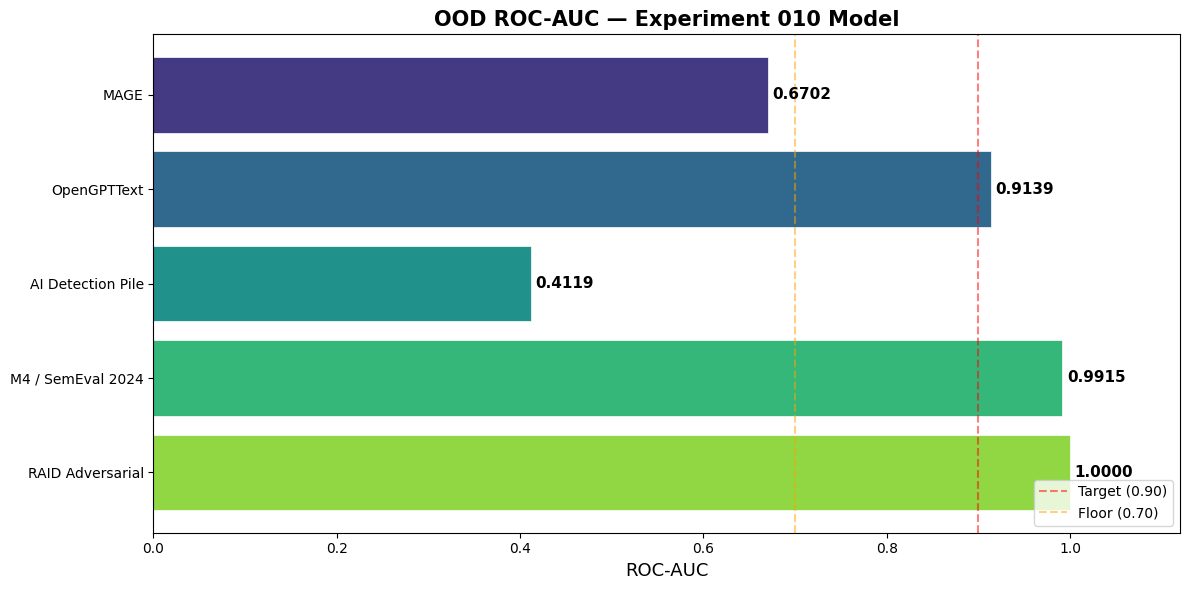

In [11]:
# ROC-AUC bar chart
if all_results:
    datasets_list = list(all_results.keys())
    aucs = [all_results[d]['ROC-AUC'] for d in datasets_list]

    fig, ax = plt.subplots(figsize=(12, 6))
    colors = sns.color_palette('viridis', len(datasets_list))
    bars = ax.barh(datasets_list, aucs, color=colors, edgecolor='white', linewidth=0.5)
    for bar, val in zip(bars, aucs):
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
                f'{val:.4f}', va='center', fontsize=11, fontweight='bold')
    ax.set_xlim(0, 1.12)
    ax.set_xlabel('ROC-AUC', fontsize=13)
    ax.set_title('OOD ROC-AUC — Experiment 010 Model', fontsize=15, fontweight='bold')
    ax.axvline(x=0.9, color='red', linestyle='--', alpha=0.5, label='Target (0.90)')
    ax.axvline(x=0.7, color='orange', linestyle='--', alpha=0.5, label='Floor (0.70)')
    ax.legend(loc='lower right')
    ax.invert_yaxis()
    plt.tight_layout()
    plt.savefig(ARTIFACTS_DIR / 'ood_roc_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()

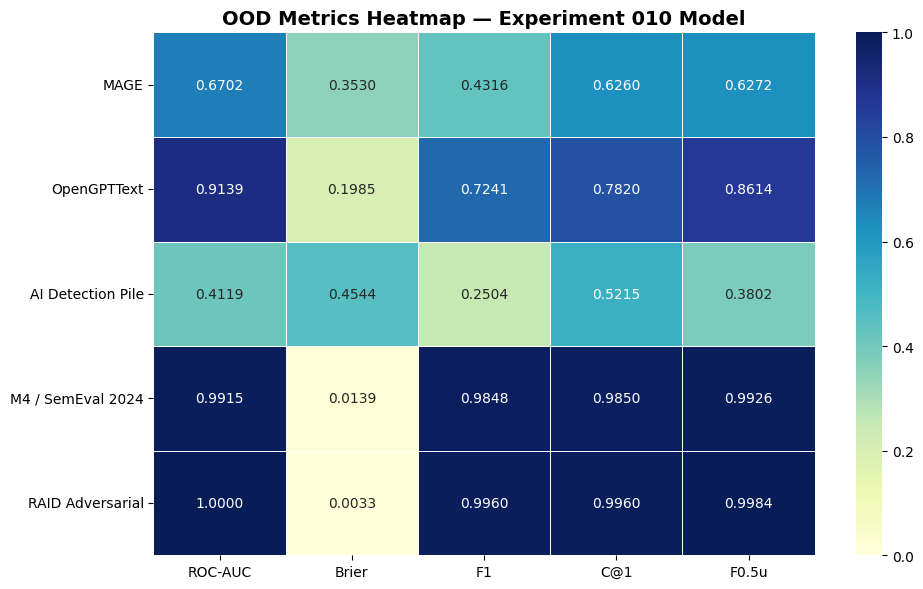

In [12]:
# Metrics heatmap
if all_results:
    datasets_list = list(all_results.keys())
    metrics_names = ['ROC-AUC', 'Brier', 'F1', 'C@1', 'F0.5u']
    data = np.array([[all_results[d].get(m, 0) for m in metrics_names] for d in datasets_list])

    fig, ax = plt.subplots(figsize=(10, max(6, len(datasets_list) * 0.8)))
    sns.heatmap(data, annot=True, fmt='.4f', xticklabels=metrics_names,
                yticklabels=datasets_list, cmap='YlGnBu', linewidths=0.5,
                ax=ax, vmin=0, vmax=1)
    ax.set_title('OOD Metrics Heatmap — Experiment 010 Model', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(ARTIFACTS_DIR / 'ood_metrics_heatmap.png', dpi=150, bbox_inches='tight')
    plt.show()

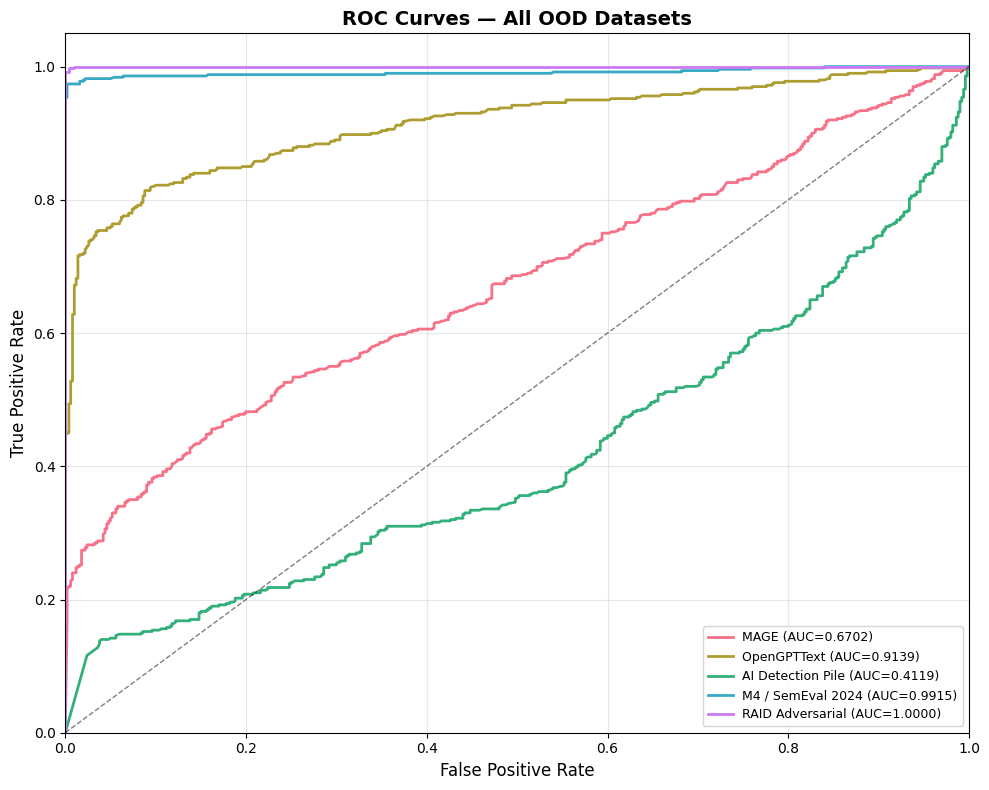

In [13]:
# ROC curves overlay
if all_probs_dict:
    fig, ax = plt.subplots(figsize=(10, 8))
    colors = sns.color_palette('husl', len(all_probs_dict))
    for (name, probs), color in zip(all_probs_dict.items(), colors):
        labels = all_labels_dict[name]
        fpr, tpr, _ = roc_curve(labels, probs)
        roc_auc_val = auc(fpr, tpr)
        ax.plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC={roc_auc_val:.4f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.05])
    ax.set_xlabel('False Positive Rate', fontsize=12)
    ax.set_ylabel('True Positive Rate', fontsize=12)
    ax.set_title('ROC Curves — All OOD Datasets', fontsize=14, fontweight='bold')
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(ARTIFACTS_DIR / 'ood_roc_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

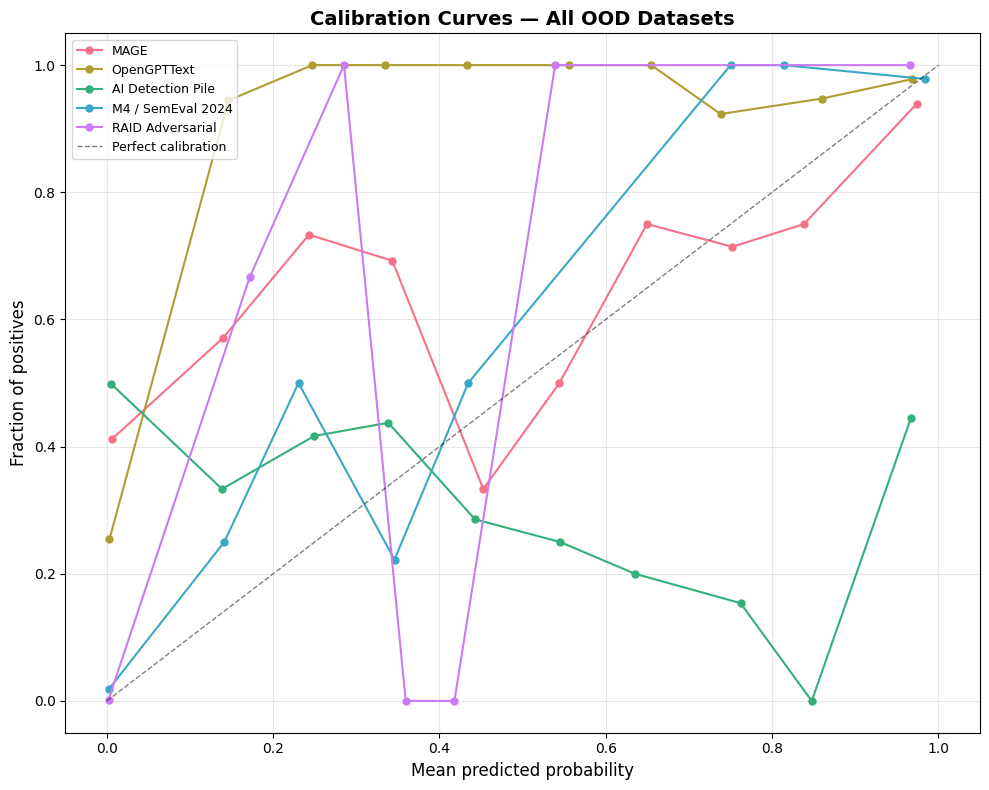

In [14]:
# Calibration curves
if all_probs_dict:
    fig, ax = plt.subplots(figsize=(10, 8))
    colors = sns.color_palette('husl', len(all_probs_dict))
    n_bins = 10
    for (name, probs), color in zip(all_probs_dict.items(), colors):
        labels = all_labels_dict[name]
        probs_arr = np.array(probs)
        labels_arr = np.array(labels)
        bin_means, bin_true = [], []
        for i in range(n_bins):
            lo = i / n_bins
            hi = (i + 1) / n_bins
            mask = (probs_arr >= lo) & (probs_arr < hi)
            if mask.sum() > 0:
                bin_means.append(probs_arr[mask].mean())
                bin_true.append(labels_arr[mask].mean())
        ax.plot(bin_means, bin_true, 'o-', color=color, label=name, markersize=5)
    ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5, label='Perfect calibration')
    ax.set_xlabel('Mean predicted probability', fontsize=12)
    ax.set_ylabel('Fraction of positives', fontsize=12)
    ax.set_title('Calibration Curves — All OOD Datasets', fontsize=14, fontweight='bold')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(ARTIFACTS_DIR / 'ood_calibration_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

## 12. Save Results & Generate Draft

In [15]:
# Build combined results dict
combined = {
    'model': ADAPTER_REPO,
    'base_model': BASE_MODEL,
    'max_samples_per_dataset': MAX_SAMPLES_PER_DATASET,
    'datasets_evaluated': len(all_results),
    'results': all_results,
}

if all_results:
    combined['summary'] = {
        'avg_roc_auc': float(avg_auc),
        'min_roc_auc': float(min_auc),
        'weakest_dataset': min_auc_ds,
        'avg_brier': float(avg_brier),
        'avg_f1': float(avg_f1),
        'avg_c_at_1': float(avg_c1),
        'avg_f05u': float(avg_f05u),
    }

# Save combined results JSON
with open(ARTIFACTS_DIR / 'all_ood_results.json', 'w') as f:
    json.dump(combined, f, indent=2)

# Save per-dataset predictions
for name in all_probs_dict:
    key = name.lower().replace(' ', '_').replace('/', '_')
    with open(ARTIFACTS_DIR / f'{key}_predictions.json', 'w') as f:
        json.dump({'probabilities': all_probs_dict[name], 'labels': all_labels_dict[name]}, f)

# Generate results draft markdown
if all_results:
    lines = []
    lines.append('# Results: 011-extensive-ood-evals\n')
    lines.append(f'**Date**: {pd.Timestamp.now().strftime("%Y-%m-%d")}')
    lines.append('**Author**: tanish\n')
    lines.append('## Results Table\n')
    lines.append('| Dataset | ROC-AUC | Brier | F1 | C@1 | F0.5u |')
    lines.append('|---------|---------|-------|-----|------|-------|')
    for name, m in all_results.items():
        lines.append(f'| {name} | {m["ROC-AUC"]:.4f} | {m["Brier"]:.4f} | {m["F1"]:.4f} | {m["C@1"]:.4f} | {m["F0.5u"]:.4f} |')
    s = combined.get('summary', {})
    if s:
        lines.append(f'| **AVERAGE** | **{s["avg_roc_auc"]:.4f}** | **{s["avg_brier"]:.4f}** | **{s["avg_f1"]:.4f}** | **{s["avg_c_at_1"]:.4f}** | **{s["avg_f05u"]:.4f}** |')
    results_md = '\n'.join(lines)
    with open(ARTIFACTS_DIR / 'results_draft.md', 'w') as f:
        f.write(results_md)
    print(results_md)

print('\n✅ All results saved locally to artifacts/')

# Results: 011-extensive-ood-evals

**Date**: 2026-03-02
**Author**: tanish

## Results Table

| Dataset | ROC-AUC | Brier | F1 | C@1 | F0.5u |
|---------|---------|-------|-----|------|-------|
| MAGE | 0.6702 | 0.3530 | 0.4316 | 0.6260 | 0.6272 |
| OpenGPTText | 0.9139 | 0.1985 | 0.7241 | 0.7820 | 0.8614 |
| AI Detection Pile | 0.4119 | 0.4544 | 0.2504 | 0.5215 | 0.3802 |
| M4 / SemEval 2024 | 0.9915 | 0.0139 | 0.9848 | 0.9850 | 0.9926 |
| RAID Adversarial | 1.0000 | 0.0033 | 0.9960 | 0.9960 | 0.9984 |
| **AVERAGE** | **0.7975** | **0.2046** | **0.6774** | **0.7821** | **0.7720** |

✅ All results saved locally to artifacts/


## 13. Upload All Artifacts to HuggingFace

In [16]:
from huggingface_hub import HfApi

api = HfApi()

# Upload entire artifacts directory to the HF dataset repo
print(f'Uploading artifacts to {HF_RESULTS_REPO}...')

api.upload_folder(
    folder_path=str(ARTIFACTS_DIR),
    repo_id=HF_RESULTS_REPO,
    repo_type='dataset',
    path_in_repo='artifacts',
    commit_message='Upload 011 extensive OOD evaluation results',
)

print(f'\n✅ All artifacts uploaded to https://huggingface.co/datasets/{HF_RESULTS_REPO}')
print(f'\nUploaded files:')
for f in sorted(ARTIFACTS_DIR.iterdir()):
    print(f'  📄 {f.name} ({f.stat().st_size / 1024:.1f} KB)')

Uploading artifacts to hersheys-baklava/pan2026-011-ood-eval-results...


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...od_calibration_curves.png: 100%|##########|  210kB /  210kB            

  ...s/ood_metrics_heatmap.png: 100%|##########| 89.8kB / 89.8kB            

  ...ts/ood_roc_comparison.png: 100%|##########| 63.3kB / 63.3kB            

  ...ifacts/ood_roc_curves.png: 100%|##########|  132kB /  132kB            


✅ All artifacts uploaded to https://huggingface.co/datasets/hersheys-baklava/pan2026-011-ood-eval-results

Uploaded files:
  📄 ai_detection_pile_predictions.json (21.5 KB)
  📄 ai_detection_pile_results.json (0.1 KB)
  📄 all_ood_results.json (1.4 KB)
  📄 m4___semeval_2024_predictions.json (16.3 KB)
  📄 m4___semeval_2024_results.json (0.1 KB)
  📄 mage_predictions.json (21.2 KB)
  📄 mage_results.json (0.1 KB)
  📄 ood_calibration_curves.png (205.2 KB)
  📄 ood_metrics_heatmap.png (87.7 KB)
  📄 ood_roc_comparison.png (61.8 KB)
  📄 ood_roc_curves.png (128.8 KB)
  📄 opengpttext_predictions.json (19.9 KB)
  📄 opengpttext_results.json (0.1 KB)
  📄 raid_adversarial_predictions.json (15.8 KB)
  📄 raid_adversarial_results.json (0.1 KB)
  📄 results_draft.md (0.6 KB)
